# Using genomic-benchmarks-data

This tutorial demonstrates dataset discovery, metadata, loading, caching, and quality-control (QC) results with the full package. The full package exposes all published splits, including `test` data.

You will learn how to:

- discover collections, datasets, and the benchmark core set;
- present dictionary results in a human-readable form;
- inspect available filter values and metadata;
- load data and locate cached files; and
- explore QC results, summaries, and self-contained reports.

Install the package if it is not already available in this environment:

```python
%pip install genomic-benchmarks-data
```

In [1]:
from IPython.display import display
import pandas as pd
import genomic_benchmarks_data as gbd

from utils import display_qc_report

## Discover datasets

Package discovery functions return ordinary Python dictionaries that can be used directly in code. The next cell shows the raw result first, followed by the same dictionary rendered with `pretty()` for easier reading.

In [6]:
collections = gbd.list_collections()
collections

{'BEACON': 'https://doi.org/10.52202/079017-2949',
 'GUE_v2': 'https://doi.org/10.48550/arXiv.2306.15006',
 'OmniGenBench': 'https://doi.org/10.48550/arXiv.2505.14402',
 'genomic-benchmarks': 'https://doi.org/10.1186/s12863-023-01123-8',
 'mRNABench': 'https://doi.org/10.1101/2025.07.05.662870',
 'miRBench': 'https://doi.org/10.1093/bioinformatics/btaf233',
 'nucleotide_benchmarks': 'https://doi.org/10.1038/s41592-024-02523-z'}

In [7]:
gbd.pretty(collections)

BEACON,https://doi.org/10.52202/079017-2949
GUE_v2,https://doi.org/10.48550/arXiv.2306.15006
OmniGenBench,https://doi.org/10.48550/arXiv.2505.14402
genomic-benchmarks,https://doi.org/10.1186/s12863-023-01123-8
mRNABench,https://doi.org/10.1101/2025.07.05.662870
miRBench,https://doi.org/10.1093/bioinformatics/btaf233
nucleotide_benchmarks,https://doi.org/10.1038/s41592-024-02523-z


### Select the core set

The core set is a selected subset of benchmarks. Pass `core_set=True` to select it, or `core_set=False` to select its complement. Core-set selection can be combined with the other dataset filters.

In [8]:
core_datasets = gbd.list_datasets(core_set=True)
gbd.pretty(core_datasets)

{'BEACON': {'CRISPROnTarget': 'Prediction of the knockout efficacy of single-guide RNA '
                              '(sgRNA) directed by Cas proteins in gene editing within '
                              'specific target sites.'},
 'GUE_v2': {'transcription_factor_prediction_mouse_4': 'Prediction of transcription '
                                                       'factor binding sites (mouse, '
                                                       'subset 4)',
            'epigenetic_marks_prediction_H3K4me3': 'Prediction of epigenetic marks '
                                                   '(H3K4me3 histone modifications) in '
                                                   'yeast'},
 'OmniGenBench': {'pro_seq_m_esculenta': 'Prediction of enhancer elements in Manihot '
                                         'esculenta seedlings (plant)',
                  'promoter_strength_protoplast': 'Prediction of promoter strength in '
                                                  'protoplasts (plant)'},
 'genomic-benchmarks': {'drosophila_enhancers_stark': 'Prediction of enhancers'},
 'mRNABench': {'translation-efficiency-human': 'Prediction of translation efficiency '
                                               'from sequence.',
               'rnahl-human': 'Prediction of mRNA half-life from sequence. Target is '
                              'first PCA component of half-life measurments across 39 '
                              'human aggregated datasets. '},
 'miRBench': {'AGO2_eCLIP_Manakov2022': 'Prediction of miRNA binding site'}}

This tutorial uses the small core-set dataset `BEACON/CRISPROnTarget`, which provides `train`, `val`, and `test` splits. Change the two values in the next cell to explore another dataset.

In [9]:
COLLECTION = "BEACON"
DATASET = "CRISPROnTarget"

### Explore available filter values

`list_dataset_filters()` shows the filters accepted by `list_datasets()` and their currently available values. 

In [18]:
filter_values = gbd.list_dataset_filters()
gbd.pretty(filter_values)


collection,BEACONGUE_v2OmniGenBenchgenomic-benchmarksmRNABenchmiRBenchnucleotide_benchmarks
molecular_level,DNARNA
task_category,Engineering PredictionEpigenomic PredictionMolecular Interaction PredictionRNA / Transcript ClassificationRNA Processing PredictionRNA Stability PredictionSequence AnnotationSpecies ClassificationTranslation Efficiency Prediction
task_type,Binary classificationRegression
species,Arabidopsis thalianaChlamydomonas reinhardtiiDrosophila melanogasterGlycine maxHomo sapiensHomo sapiens|Caenorhabditis elegansManihot esculentaMedicago truncatulaMus musculusNicotiana tabacumOryza sativaSaccharomyces cerevisiaeSolanum lycopersicumSorghum bicolorTrifolium pratenseTriticum aestivumZea mays
core_set,TrueFalse


Passing `COLLECTION` limits the metadata-derived values to the selected collection; omit it to inspect values across the entire package.

In [19]:
filter_values = gbd.list_dataset_filters(COLLECTION)
gbd.pretty(filter_values)

collection,BEACON
molecular_level,DNARNA
task_category,Engineering PredictionRNA Processing PredictionTranslation Efficiency Prediction
task_type,Regression
species,Homo sapiens
core_set,TrueFalse


## Inspect metadata

Use the targeted accessors for ordinary exploration. `load_metadata()` is also available when the complete packaged metadata is needed for bulk processing.

In [20]:
dataset_info = gbd.get_dataset_info(COLLECTION, DATASET)
gbd.pretty(dataset_info)

dataset_name,CRISPROnTarget
task_description,Prediction of the knockout efficacy of single-guide RNA (sgRNA) directed by Cas proteins in gene editing within specific target sites.
dataset_doi,https://doi.org/10.1186/s13059-018-1459-4
species,Homo sapiens
task_type,Regression
seq_col,seq
label_col,label
label_categories,None
splits,trainvaltest
major_version,v1
task_category,Engineering Prediction


In [29]:
split_info = gbd.get_split_info(COLLECTION, DATASET, "train")
gbd.pretty(split_info)

{'seq_length': {'seq': {'min': 23, 'max': 23, 'median': 23}},
 'seq_alphabet': {'seq': ['A', 'C', 'G', 'T']},
 'labels': {'min': 0.0277828845416346,
            'max': 0.692699498961697,
            'median': 0.216143386109033},
 'dataset_size': 1453,
 'class_ratio': None,
 'all_columns': ['id', 'row_index', 'seq', 'label'],
 'sha256': '66cf1af39463cfb3acb9aca56c13fde6e2c31cd170470e874e761d52d6e19db5'}

## Download and load data

`download_dataset()` downloads the complete cached file and returns its path. 

In [28]:
cached_test_path = gbd.download_dataset(COLLECTION, DATASET, "test")
cached_test_path

PosixPath('/homes/ssamm10/.cache/genomic_benchmarks_data/data/BEACON/CRISPROnTarget/v1/test/079f02744eed3c92be96817ee5c73a3eeeca53112aecaba5cc09c0e18ef61be7/CRISPROnTarget_test.csv.gz')

`load_dataset()` downloads and loads the dataset in a Pandas DataFrame. By default, `train` and `val` contain the sequence and label columns needed for the task.

In [22]:
train = gbd.load_dataset(COLLECTION, DATASET, "train")
train.head()

,seq,label
0,TTCACTGCGCAGCCTGGCATTGG,0.261026
1,TTCATTTACTGACTTCAGATTGG,0.088202
2,AAAGAGGTCGAAGATGTAGCGGG,0.103584
3,CAAGATTGATCAGAAAGCTGTGG,0.274124
4,TTCACTGCCAGTTCTCCGCGTGG,0.315928


The default `test` view starts with stable `id` and zero-based `row_index`, followed by the sequence and label columns. These identifiers make predictions traceable to examples.

In [25]:
test = gbd.load_dataset(COLLECTION, DATASET, "test")
test.head()

,id,row_index,seq,label
0,BEACON:CRISPROnTarget:v1:test:0000000,0,GCAGACAAGAAGCGCAGGACAGG,0.208640
1,BEACON:CRISPROnTarget:v1:test:0000001,1,CCTTGCCTCCGCGAGCTCCGCGG,0.413518
2,BEACON:CRISPROnTarget:v1:test:0000002,2,ATCTGCCAGGCACTCAGCAATGG,0.313632
3,BEACON:CRISPROnTarget:v1:test:0000003,3,TTACGAGTTCACCTGTGTGAAGG,0.221238
4,BEACON:CRISPROnTarget:v1:test:0000004,4,CTGGCCCGTGTGAATGCCCTCGG,0.252790


Use `columns="all"` to include identifiers and any other auxiliary columns for `train` and `val` splits. 

In [24]:
train_all = gbd.load_dataset(COLLECTION, DATASET, "train", columns="all")
train_all.head()

,id,row_index,seq,label
0,BEACON:CRISPROnTarget:v1:train:0000000,0,TTCACTGCGCAGCCTGGCATTGG,0.261026
1,BEACON:CRISPROnTarget:v1:train:0000001,1,TTCATTTACTGACTTCAGATTGG,0.088202
2,BEACON:CRISPROnTarget:v1:train:0000002,2,AAAGAGGTCGAAGATGTAGCGGG,0.103584
3,BEACON:CRISPROnTarget:v1:train:0000003,3,CAAGATTGATCAGAAAGCTGTGG,0.274124
4,BEACON:CRISPROnTarget:v1:train:0000004,4,TTCACTGCCAGTTCTCCGCGTGG,0.315928


## Explore QC results

Class QC compares classes in individual splits. Split QC compares two splits for leakage. 

In [39]:
class_qc_metrics = gbd.list_qc_metrics("class")
gbd.pretty(class_qc_metrics)

['Duplicate Sequences between Labels',
 'Per position nucleotide content',
 'Per position reversed nucleotide content',
 'Per sequence GC content',
 'Per sequence dinucleotide content',
 'Per sequence nucleotide content',
 'Sequence Duplications within Labels',
 'Sequence lengths',
 'Unique bases']

In [40]:
split_qc_metrics = gbd.list_qc_metrics("split")
gbd.pretty(split_qc_metrics)

['Data Leakage']

`load_qc_results()` returns parsed results; users who need the original combined CSV can instead call `download_qc_csv()`.

In [41]:
class_qc = gbd.load_qc_results("class")
gbd.pretty(class_qc)

{'BEACON': {'CRISPROnTarget': {'test': {'Unique bases': {'flag': 'Pass',
                                                         'accuracy': None,
                                                         'au_pr': None,
                                                         'au_roc': None},
                                        'Sequence Duplications within Labels': {'flag': 'Pass',
                                                                                'accuracy': None,
                                                                                'au_pr': None,
                                                                                'au_roc': None},
                                        'Duplicate Sequences between Labels': {'flag': 'Pass',
                                                                               'accuracy': None,
                                                                               'au_pr': None,
                                                                               'au_roc': None},
                                        'Sequence lengths': {'flag': 'Unknown',
                                                             'accuracy': None,
                                                             'au_pr': None,
                                                             'au_roc': None},
                                        'Per sequence GC content': {'flag': 'Unknown',
                                                                    'accuracy': None,
                                                                    'au_pr': None,
                                                                    'au_roc': None},
                                        'Per sequence nucleotide content': {'flag': 'Unknown',
                                                                            'accuracy': None,
                                                                            'au_pr': None,
                                                                            'au_roc': None},
                                        'Per sequence dinucleotide content': {'flag': 'Unknown',
                                                                              'accuracy': None,
                                                                              'au_pr': None,
                                                                              'au_roc': None},
                                        'Per position nucleotide content': {'flag': 'Unknown',
                                                                            'accuracy': None,
                                                                            'au_pr': None,
                                                                            'au_roc': None},
                                        'Per position reversed nucleotide content': {'flag': 'Unknown',
                                                                                     'accuracy': None,
                                                                                     'au_pr': None,
                                                                                     'au_roc': None}},
                               'val': {'Unique bases': {'flag': 'Pass',
                                                        'accuracy': None,
                                                        'au_pr': None,
                                                        'au_roc': None},
                                       'Sequence Duplications within Labels': {'flag': 'Pass',
                                                                               'accuracy': None,
                                                                               'au_pr': None,
                                                                               'au_roc': None},
                                       'Duplicate Sequences between Labels'

In [42]:
split_qc = gbd.load_qc_results("split")
gbd.pretty(split_qc)

{'BEACON': {'Isoform': {'overall': {'statistic': 'Split leakage '
                                                 '(percentage_of_leaked_queries)',
                                    'flag': 'Fail'},
                        'comparisons': {'train': {'val': {'Data Leakage': {'flag': 'Fail',
                                                                           'percentage_of_leaked_queries': '36.48%',
                                                                           'percentage_of_leaked_targets': '27.44%'}},
                                                  'test': {'Data Leakage': {'flag': 'Fail',
                                                                            'percentage_of_leaked_queries': '37.24%',
                                                                            'percentage_of_leaked_targets': '29.89%'}}}}},
            'MeanRibosomeLoading': {'overall': {'statistic': 'Split leakage '
                                                             '(percentage_of_leaked_queries)',
                                                'flag': 'Pass'},
                                    'comparisons': {'train': {'test': {'Data Leakage': {'flag': 'Pass',
                                                                                        'percentage_of_leaked_queries': '0.00%',
                                                                                        'percentage_of_leaked_targets': '0.00%'}},
                                                              'val': {'Data Leakage': {'flag': 'Pass',
                                                                                       'percentage_of_leaked_queries': '0.00%',
                                                                                       'percentage_of_leaked_targets': '0.00%'}}}}},
            'CRISPROnTarget': {'overall': {'statistic': 'Split leakage '
                                                        '(percentage_of_leaked_queries)',
                                           'flag': 'Pass'},
                               'comparisons': {'train': {'val': {'Data Leakage': {'flag': 'Pass',
                                                                                  'percentage_of_leaked_queries': '0.00%',
                                                                                  'percentage_of_leaked_targets': '0.00%'}},
                                                         'test': {'Data Leakage': {'flag': 'Pass',
                                                                                   'percentage_of_leaked_queries': '0.00%',
                                                                                   'percentage_of_leaked_targets': '0.00%'}}}}}},
 'GUE_v2': {'core_promoter_detection_all': {'overall': {'statistic': 'Split leakage '
                                                                     '(percentage_of_leaked_queries)',
                                                        'flag': 'Warning'},
                                            'comparisons': {'train': {'val': {'Data Leakage': {'flag': 'Warning',
                                                                                               'percentage_of_leaked_queries': '1.74%',
                                                                                               'percentage_of_leaked_targets': '0.24%'}},
                                                                      'test': {'Data Leakage': {'flag': 'Warning',
                                                                                                'percentage_of_leaked_queries': '1.45%',
                                                                                                'percentage_of_leaked_targets': '0.23%'}}}}},
            'core_promoter_detection_notata': {'overall': {'statistic': 'Split leakage '
                                                                        '(percentage_of_leaked_queries)',
        

### Inspect QC for the selected dataset

The first table shows the `train`-split class checks and any available scores. The second shows the relevant split-leakage comparison.

In [46]:
dataset_split_class_qc = class_qc[COLLECTION][DATASET]["train"]
gbd.pretty(dataset_split_class_qc)

{'Unique bases': {'flag': 'Pass', 'accuracy': None, 'au_pr': None, 'au_roc': None},
 'Sequence Duplications within Labels': {'flag': 'Pass',
                                         'accuracy': None,
                                         'au_pr': None,
                                         'au_roc': None},
 'Duplicate Sequences between Labels': {'flag': 'Pass',
                                        'accuracy': None,
                                        'au_pr': None,
                                        'au_roc': None},
 'Sequence lengths': {'flag': 'Pass',
                      'accuracy': 0.5003441156228493,
                      'au_pr': 0.5003441156228493,
                      'au_roc': 0.5},
 'Per sequence GC content': {'flag': 'Pass',
                             'accuracy': 0.5375086028905712,
                             'au_pr': 0.5226575903860866,
                             'au_roc': 0.5447734188199362},
 'Per sequence nucleotide content': {'flag': 'Warning',
                                     'accuracy': 0.578114246386786,
                                     'au_pr': 0.5667324855945897,
                                     'au_roc': 0.6020884725711536},
 'Per sequence dinucleotide content': {'flag': 'Pass',
                                       'accuracy': 0.5746730901582932,
                                       'au_pr': 0.5615124254838183,
                                       'au_roc': 0.5904022720641453},
 'Per position nucleotide content': {'flag': 'Pass',
                                     'accuracy': 0.5788024776324845,
                                     'au_pr': 0.5514016412079391,
                                     'au_roc': 0.5789614287175873},
 'Per position reversed nucleotide content': {'flag': 'Pass',
                                              'accuracy': 0.5788024776324845,
                                              'au_pr': 0.5514016412079391,
                                              'au_roc': 0.5789614287175873}}

In [47]:
dataset_split_qc = split_qc[COLLECTION][DATASET]["comparisons"]["train"]["test"]
gbd.pretty(dataset_split_qc)


{'Data Leakage': {'flag': 'Pass',
                  'percentage_of_leaked_queries': '0.00%',
                  'percentage_of_leaked_targets': '0.00%'}}

In [48]:
passing_class_qc = gbd.filter_datasets_by_qc("class", flag="Pass")
gbd.pretty(passing_class_qc)

GUE_v2,enhancer_promoter_interaction_GM12878enhancer_promoter_interaction_HeLa_S3epigenetic_marks_prediction_H3K14acepigenetic_marks_prediction_H3K4me3transcription_factor_prediction_mouse_0transcription_factor_prediction_mouse_1transcription_factor_prediction_mouse_4
genomic-benchmarks,drosophila_enhancers_stark
miRBench,AGO2_CLASH_Hejret2023AGO2_eCLIP_Klimentova2022AGO2_eCLIP_Manakov2022


In [49]:
passing_split_qc = gbd.filter_datasets_by_qc("split", flag="Pass")
gbd.pretty(passing_split_qc)


BEACON,CRISPROnTargetMeanRibosomeLoading
GUE_v2,epigenetic_marks_prediction_H3epigenetic_marks_prediction_H3K4me3transcription_factor_prediction_mouse_0transcription_factor_prediction_mouse_2transcription_factor_prediction_mouse_4
OmniGenBench,poly_a_arabidopsis_thalianapoly_a_chlamydomonas_reinhardtiipoly_a_medicago_truncatulapoly_a_trifolium_pratensepro_seq_m_esculentasplicing_arabidopsis_thaliana_acceptorsplicing_arabidopsis_thaliana_donor
mRNABench,rnahl-mousetranslation-efficiency-humantranslation-efficiency-mouse
nucleotide_benchmarks,promoter_tata


### Compare QC across collections

The class plot counts dataset–split–check results. The split plot counts detailed comparisons between available splits.

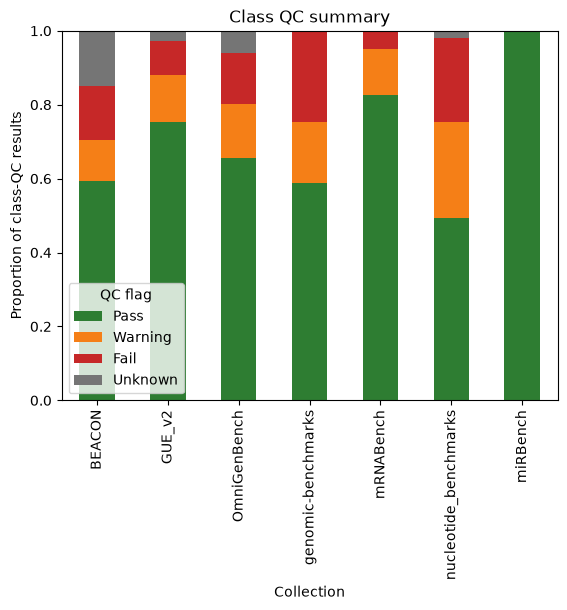

In [15]:
class_summary_plot = gbd.plot_qc_summary("class")


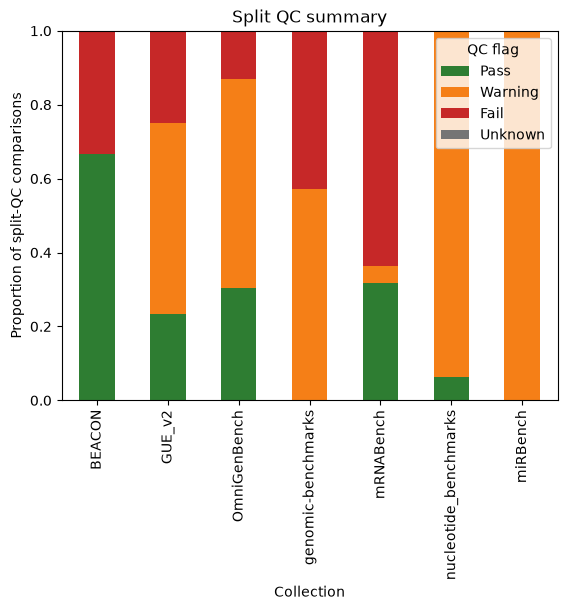

In [16]:
split_summary_plot = gbd.plot_qc_summary("split")


## Open self-contained QC reports

Run these cells locally to explore the interactive reports. Their large embedded HTML output is intentionally not stored in the repository notebooks.

<iframe srcdoc="<!DOCTYPE html>
<html lang="en">
<head>
 <meta charset="UTF-8">
 <meta name="viewport" content="width=device-width, initial-scale=1.0">
 <title>CRISPROnTarget_train.csv.gz: high vs low (seq) - gb-qc</title>
 <style>/* Make sure the root uses border-box sizing and doesn't allow the
 page to horizontally overflow. Individual <pre> blocks will
 still allow internal horizontal scrolling. */
html, body {
 box-sizing: border-box;
 overflow-x: hidden; /* prevent accidental page-wide horizontal scroll */
 margin: 0;
 padding: 0;
 background: #ffffff;
}
body {
 font-family: Arial, sans-serif;
 max-width: 100%; /* Prevents content from exceeding the viewport width */
}
.sidebar {
 width: 220px;
 background: #f4f4f4;
 padding: 15px;
 box-shadow: 2px 0 5px rgba(0, 0, 0, 0.1);
 height: 100vh; /* Full height */
 position: fixed; /* Fixed position */
 overflow-y: auto;
 z-index: 1000; /* Ensures it stays above other elements */
}
.sidebar a {
 display: inline-block;
 margin-left: 10px;
 text-decoration: none;
 color: #333;
 width: 175px;
}
.sidebar-item {
 display: flex;
 align-items: center;
 margin-bottom: 10px;
}
.status-icon {
 display: inline-flex;
 width: 40px;
 height: 40px;
 line-height: 40px;
 border-radius: 50%;
 color: white;
 font-size: 25px;
 font-family: verdana;
 text-align: center;
 justify-content: center;
}
.status-icon-small {
 display: inline-flex;
 width: 28px;
 height: 28px;
 line-height: 28px;
 border-radius: 50%;
 color: white;
 font-size: 14px;
 font-family: verdana;
 text-align: center;
 justify-content: center;
 margin: 0 4px 4px 0;
}
.status-pass { background-color: #2e7d32; color: #ffffff; }
.status-warn { background-color: #f57f17; color: #ffffff; }
.status-fail { background-color: #c62828; color: #ffffff; }
.status-unknown { background-color: #8a8983; color: #ffffff; }
.nucleotide-flags-container {
 display: flex;
 flex-wrap: wrap;
 gap: 10px;
 margin: -15px 0 15px 60px;
 align-items: flex-start;
}
.nucleotide-flag-item {
 display: flex;
 flex-direction: column;
 align-items: center;
 gap: 4px;
}
.nucleotide-flag-item .nucleotide-label {
 font-size: 14px;
 font-weight: bold;
 text-align: center;
 min-width: 24px;
}
.container {
 /* in some layouts the flex parent can grow to fit unbreakable children;
 make sure the container can shrink so .content's min-width:0 works */
 min-width: 0;
 box-sizing: border-box;
}
.content {
 margin-left: 260px;
 padding: 10px;
 padding-right: 8%;
 width: min(calc(100% - 260px), 1000px); /* Adjust width to avoid overlap */
 overflow-x: hidden;
 /* allow flex child to shrink below its content width so long lines
 inside (e.g. long sequences in <pre>) don't expand the whole page */
 min-width: 0;
 box-sizing: border-box;
}
#sequence-duplication-levels table {
 table-layout: fixed; /* Ensures columns respect defined widths */
 width: 100%;
 border-collapse: collapse;
}
#sequence-duplication-levels table th,
#sequence-duplication-levels table td {
 padding: 8px;
 border: 1px solid #ddd;
}
#sequence-duplication-levels table td {
 white-space: nowrap;
 overflow: hidden;
 text-overflow: ellipsis;
}
.count_column { width: 45px; }
.sequence_column { width: 95%; }
h1 { text-align: center; margin-bottom: 50px; }
section { margin-bottom: 50px; }
h2 { color: #333; border-bottom: 2px solid #ddd; padding-bottom: 5px; margin-left: 10px; }
h3 { color: #555; margin-bottom: 15px; }
.chart-container { margin-bottom: 30px; }
.data-item { font-size: 1.2em; margin-bottom: 10px; }
.data-item span { font-weight: bold; font-size: 1em; }

/* The key/value table a check leads with: the section's own table, addressed as
 a direct child so that a findings listing nested deeper inside the same
 section (see .qc-listing in report_design.css) keeps its own look. */
.table-section > table { width: 100%; border-collapse: collapse; margin: 20px 0; }
.table-section > table td { padding: 10px; border: 1px solid #ddd; text-align: center; }
.table-section > table td:first-child { text-align: left; width:
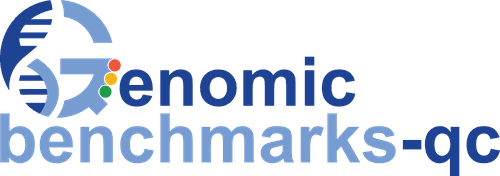

In [50]:
class_report = gbd.get_class_qc_report(COLLECTION, DATASET, split="train", seq_col="seq")
display_qc_report(class_report)

<iframe srcdoc="<!DOCTYPE html>
<html lang="en">
<head>
 <meta charset="UTF-8">
 <meta name="viewport" content="width=device-width, initial-scale=1.0">
 <title>CRISPROnTarget_test.csv.gz vs CRISPROnTarget_train.csv.gz: leakage - gb-qc</title>
 <style>
 /* Make sure the root uses border-box sizing and doesn't allow the
 page to horizontally overflow. Individual <pre> blocks will
 still allow internal horizontal scrolling. */
html, body {
 box-sizing: border-box;
 overflow-x: hidden; /* prevent accidental page-wide horizontal scroll */
 margin: 0;
 padding: 0;
 background: #ffffff;
}
body {
 font-family: Arial, sans-serif;
 max-width: 100%; /* Prevents content from exceeding the viewport width */
}
.sidebar {
 width: 220px;
 background: #f4f4f4;
 padding: 15px;
 box-shadow: 2px 0 5px rgba(0, 0, 0, 0.1);
 height: 100vh; /* Full height */
 position: fixed; /* Fixed position */
 overflow-y: auto;
 z-index: 1000; /* Ensures it stays above other elements */
}
.sidebar a {
 display: inline-block;
 margin-left: 10px;
 text-decoration: none;
 color: #333;
 width: 175px;
}
.sidebar-item {
 display: flex;
 align-items: center;
 margin-bottom: 10px;
}
.status-icon {
 display: inline-flex;
 width: 40px;
 height: 40px;
 line-height: 40px;
 border-radius: 50%;
 color: white;
 font-size: 25px;
 font-family: verdana;
 text-align: center;
 justify-content: center;
}
.status-icon-small {
 display: inline-flex;
 width: 28px;
 height: 28px;
 line-height: 28px;
 border-radius: 50%;
 color: white;
 font-size: 14px;
 font-family: verdana;
 text-align: center;
 justify-content: center;
 margin: 0 4px 4px 0;
}
.status-pass { background-color: #2e7d32; color: #ffffff; }
.status-warn { background-color: #f57f17; color: #ffffff; }
.status-fail { background-color: #c62828; color: #ffffff; }
.status-unknown { background-color: #8a8983; color: #ffffff; }
.nucleotide-flags-container {
 display: flex;
 flex-wrap: wrap;
 gap: 10px;
 margin: -15px 0 15px 60px;
 align-items: flex-start;
}
.nucleotide-flag-item {
 display: flex;
 flex-direction: column;
 align-items: center;
 gap: 4px;
}
.nucleotide-flag-item .nucleotide-label {
 font-size: 14px;
 font-weight: bold;
 text-align: center;
 min-width: 24px;
}
.container {
 /* in some layouts the flex parent can grow to fit unbreakable children;
 make sure the container can shrink so .content's min-width:0 works */
 min-width: 0;
 box-sizing: border-box;
}
.content {
 margin-left: 260px;
 padding: 10px;
 padding-right: 8%;
 width: min(calc(100% - 260px), 1000px); /* Adjust width to avoid overlap */
 overflow-x: hidden;
 /* allow flex child to shrink below its content width so long lines
 inside (e.g. long sequences in <pre>) don't expand the whole page */
 min-width: 0;
 box-sizing: border-box;
}
#sequence-duplication-levels table {
 table-layout: fixed; /* Ensures columns respect defined widths */
 width: 100%;
 border-collapse: collapse;
}
#sequence-duplication-levels table th,
#sequence-duplication-levels table td {
 padding: 8px;
 border: 1px solid #ddd;
}
#sequence-duplication-levels table td {
 white-space: nowrap;
 overflow: hidden;
 text-overflow: ellipsis;
}
.count_column { width: 45px; }
.sequence_column { width: 95%; }
h1 { text-align: center; margin-bottom: 50px; }
section { margin-bottom: 50px; }
h2 { color: #333; border-bottom: 2px solid #ddd; padding-bottom: 5px; margin-left: 10px; }
h3 { color: #555; margin-bottom: 15px; }
.chart-container { margin-bottom: 30px; }
.data-item { font-size: 1.2em; margin-bottom: 10px; }
.data-item span { font-weight: bold; font-size: 1em; }

/* The key/value table a check leads with: the section's own table, addressed as
 a direct child so that a findings listing nested deeper inside the same
 section (see .qc-listing in report_design.css) keeps its own look. */
.table-section > table { width: 100%; border-collapse: collapse; margin: 20px 0; }
.table-section > table td { padding: 10px; border: 1px solid #ddd; text-align: center; }
.table-section > table td:first-child { te
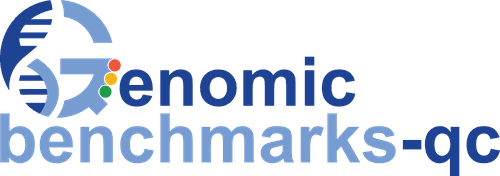

In [51]:
split_report = gbd.get_split_qc_report(COLLECTION, DATASET, split_a="train", split_b="test")
display_qc_report(split_report)